In [ ]:
# importing usefull transfer learning libraries

from tensorflow.keras.layers import Input, Lambda, Dense, Flatten
from tensorflow.keras.models import Model
from keras.applications.vgg16 import VGG16

In [ ]:
#to prevent gpu to collapse it allow using at 50% of total gpu
from tensorflow.compat.v1 import ConfigProto
from tensorflow.compat.v1 import InteractiveSession

config = ConfigProto()
config.gpu_options.per_process_gpu_memory_fraction = 0.5
config.gpu_options.allow_growth = True
session = InteractiveSession(config=config)

/usr/local/lib/python3.9/dist-packages/tensorflow/python/client/session.py:1769: UserWarning: An interactive session is already active. This can cause out-of-memory errors in some cases. You must explicitly call `InteractiveSession.close()` to release resources held by the other session(s).
  warnings.warn('An interactive session is already active. This can '


In [ ]:
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator,load_img
from tensorflow.keras.models import Sequential
import tensorflow as tf
import numpy as np
import cv2
from glob import glob
from PIL import Image
import matplotlib.pyplot as plt

In [ ]:

from keras.utils.vis_utils import plot_model
!pip install pydot
import keras.backend as K

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# re-size all the images to this
image_size = [224, 224]

train_path = '/content/drive/MyDrive/Dataset/Rice_Varieties/train_real'
valid_path = '/content/drive/MyDrive/Dataset/Rice_Varieties/val_real'

In [ ]:
vgg= VGG16(input_shape=image_size + [3], weights='imagenet', include_top=False)

58889256/58889256 [==============================] - 1s 0us/step


In [ ]:
# don't train existing weights
for layer in vgg.layers:
    layer.trainable = False

In [ ]:
folders = glob('/content/drive/MyDrive/Dataset/Rice_Varieties/train_real/*')

In [ ]:
# adding input and output layers
x = Flatten()(vgg.output)


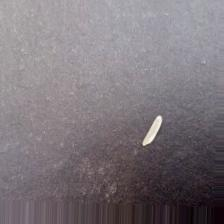

In [ ]:
from IPython.display import Image
Image('/content/drive/MyDrive/Dataset/Rice_Varieties/train_real/Seela/Seela_0_2991.jpeg', width=250, height=250)

In [ ]:
#initializing the inner layers by using sigmoid function
prediction = Dense(7, activation='softmax')(x)

# create a model object
model = Model(inputs=vgg.input, outputs=prediction)

In [ ]:
# view the structure of the model
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 block1_conv1 (Conv2D)       (None, 224, 224, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 224, 224, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 112, 112, 64)      0         
                                                                 
 block2_conv1 (Conv2D)       (None, 112, 112, 128)     73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 112, 112, 128)     147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 56, 56, 128)       0     

In [ ]:
def f1_score(y_true, y_pred): #taken from old keras source code
    true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
    possible_positives = K.sum(K.round(K.clip(y_true, 0, 1)))
    predicted_positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
    precision = true_positives / (predicted_positives + K.epsilon())
    recall = true_positives / (possible_positives + K.epsilon())
    f1_val = 2*(precision*recall)/(precision+recall+K.epsilon())
    return f1_val

In [ ]:
import tensorflow as tf
METRICS = [
      tf.keras.metrics.BinaryAccuracy(name='accuracy'),
      tf.keras.metrics.Precision(name='precision'),
      tf.keras.metrics.Recall(name='recall'),
      tf.keras.metrics.AUC(name='auc'),
        f1_score,
]

In [ ]:
import tensorflow as tf

In [ ]:
from tensorflow.keras.optimizers import Adam
opt = Adam(learning_rate=0.001)

In [ ]:

model.compile(optimizer=opt,
              loss=keras.losses.categorical_crossentropy,
              metrics=METRICS
              )

In [ ]:
# using this to tackle with loss cost and optimizer input weights by comparing the prediction and the loss function
#model.compile(
  loss='categorical_crossentropy',
  optimizer='adam',
  #matrix for accuracy
  metrics=METRICS
)

In [ ]:
# Use the Image Data Generator to import the images from the dataset
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale = 1./255,
                                   shear_range = 0.2,
                                   zoom_range = 0.2,
                                   horizontal_flip = True)

In [ ]:
#by using the image generator for importing images
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_dg = ImageDataGenerator(rescale = 1./255,
                              shear_range =0.2,
                              zoom_range = 0.2,
                              horizontal_flip = True
                              )
test_dg = ImageDataGenerator(rescale = 1./255)

In [ ]:
training_set = train_datagen.flow_from_directory('/content/drive/MyDrive/Dataset/Rice_Varieties/train_real',
                                                 target_size = (224, 224),
                                                 batch_size = 32,
                                                 class_mode = 'categorical')

Found 7852 images belonging to 7 classes.


In [ ]:
test_set = test_dg.flow_from_directory('/content/drive/MyDrive/Dataset/Rice_Varieties/val_real',
                                            target_size = (224, 224),
                                            batch_size = 32,
                                            class_mode = 'categorical')

Found 3350 images belonging to 7 classes.


In [ ]:
test_set.class_indices

{'1508': 0,
 'Seela': 1,
 'Sufaid': 2,
 'ari': 3,
 'kachi': 4,
 'kachi_kainat': 5,
 'super': 6}

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint,EarlyStopping
checkpoint=ModelCheckpoint('/content/drive/MyDrive/Dataset/Rice_Varieties.h5',
                          monitor='val_accuracy',
                          mode='auto',
                          save_best_only=True,
                          verbose=1
                           )
earlystop=EarlyStopping(monitor='val_loss',
                       min_delta=0,
                       patience=5,
                       verbose=1,
                       restore_best_weights=True
                      )

callbacks=[checkpoint,earlystop]

In [ ]:
#training my model wtih dense last layer and flatting the first layer
r = model.fit_generator(
  training_set,
  validation_data=test_set,
  epochs=50,
  steps_per_epoch=len(training_set),
  validation_steps=len(test_set),
  verbose=1,
  callbacks= callbacks,
)

<ipython-input-38-4b1dc1532e02>:2: UserWarning: `Model.fit_generator` is deprecated and will be removed in a future version. Please use `Model.fit`, which supports generators.
  r = model.fit_generator(


Epoch 1/50
246/246 [==============================] - ETA: 0s - loss: 1.2918 - accuracy: 0.8825 - precision: 0.6784 - recall: 0.3380 - auc: 0.8576 - f1_score: 0.4358
Epoch 1: val_accuracy improved from -inf to 0.90090, saving model to /content/drive/MyDrive/Dataset/Rice_Varieties.h5
246/246 [==============================] - 2239s 9s/step - loss: 1.2918 - accuracy: 0.8825 - precision: 0.6784 - recall: 0.3380 - auc: 0.8576 - f1_score: 0.4358 - val_loss: 1.0077 - val_accuracy: 0.9009 - val_precision: 0.7189 - val_recall: 0.5030 - val_auc: 0.9148 - val_f1_score: 0.5905
Epoch 2/50
246/246 [==============================] - ETA: 0s - loss: 0.8261 - accuracy: 0.9172 - precision: 0.7874 - recall: 0.5759 - auc: 0.9442 - f1_score: 0.6635
Epoch 2: val_accuracy improved from 0.90090 to 0.91394, saving model to /content/drive/MyDrive/Dataset/Rice_Varieties.h5
246/246 [==============================] - 124s 505ms/step - loss: 0.8261 - accuracy: 0.9172 - precision: 0.7874 - recall: 0.5759 - auc: 0.9

In [ ]:
model.save("vgg16.h5")

In [ ]:
import matplotlib.pyplot as plt

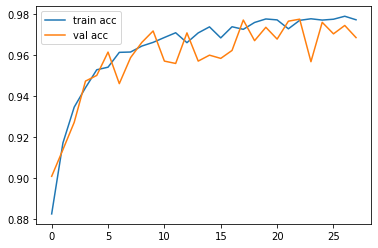

<Figure size 432x288 with 0 Axes>

In [ ]:
# plot the accuracy
plt.plot(r.history['accuracy'], label='train acc')
plt.plot(r.history['val_accuracy'], label='val acc')
plt.legend()
plt.show()
plt.savefig('AccVal_acc')

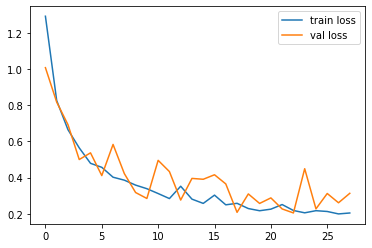

<Figure size 432x288 with 0 Axes>

In [ ]:
# plot the loss
plt.plot(r.history['loss'], label='train loss')
plt.plot(r.history['val_loss'], label='val loss')
plt.legend()
plt.show()
plt.savefig('LossVal_loss')

In [ ]:
from sklearn.calibration import calibration_curve
from matplotlib import pyplot
History=r
import matplotlib.pyplot as plt

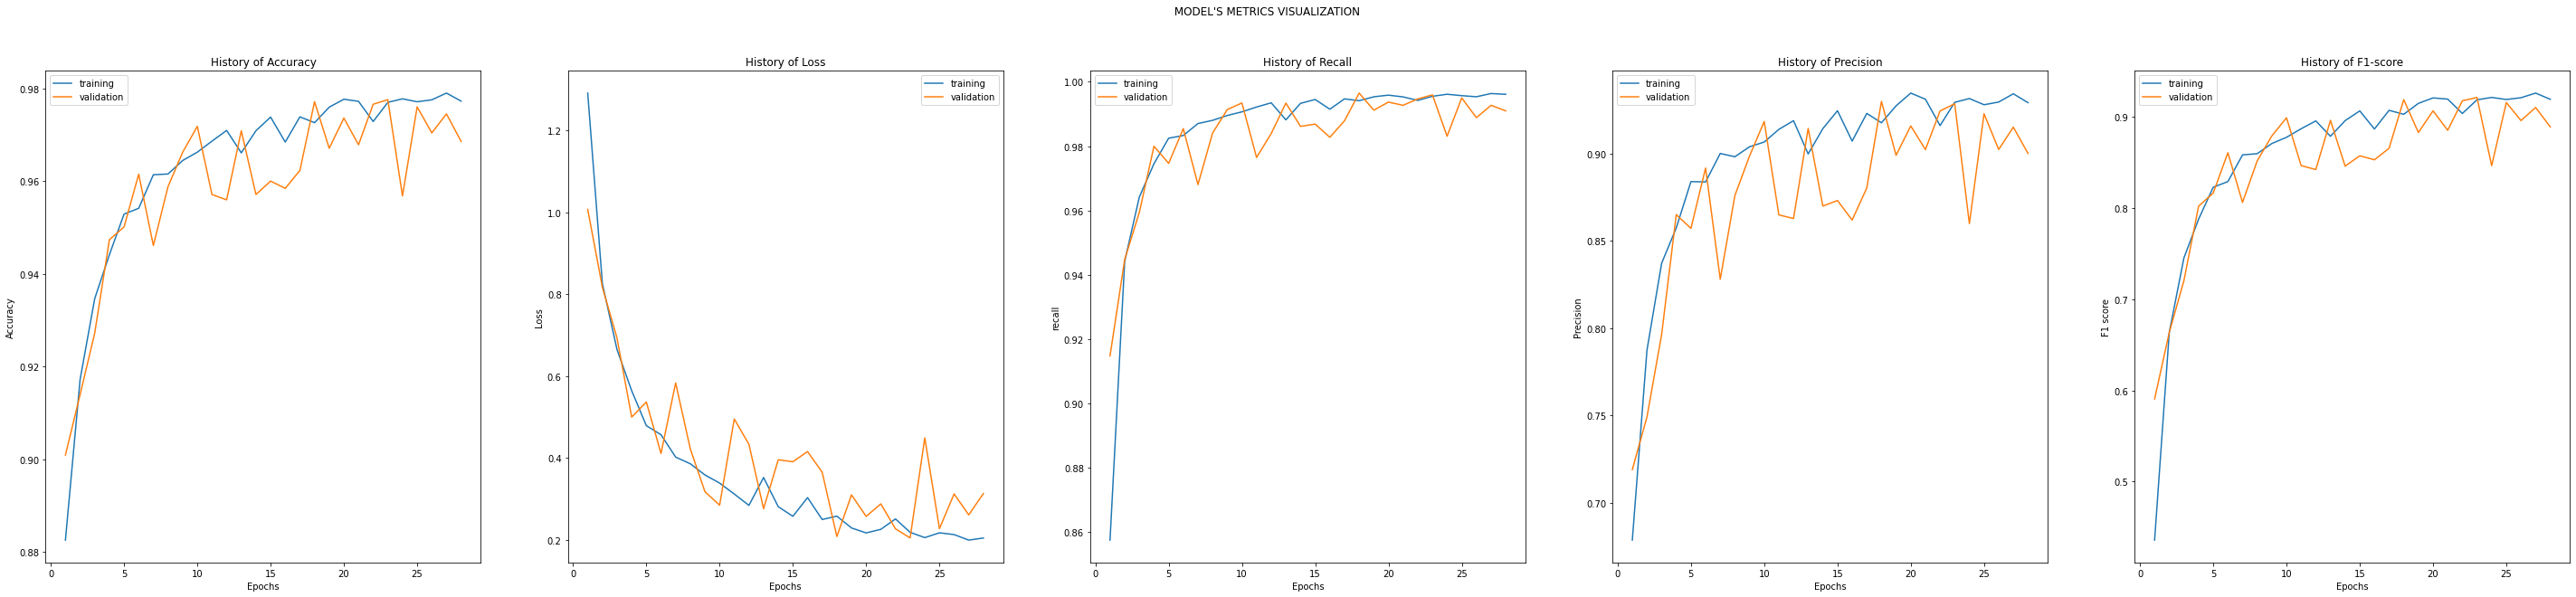

In [ ]:
#%% PLOTTING RESULTS (Train vs Validation FOLDER 1)

def Train_Val_Plot(acc,val_acc,loss,val_loss,auc,val_auc,precision,val_precision,f1,val_f1):

    fig, (ax1, ax2,ax3,ax4,ax5) = plt.subplots(1,5, figsize= (50,10))
    fig.suptitle(" MODEL'S METRICS VISUALIZATION ")

    ax1.plot(range(1, len(acc) + 1), acc)
    ax1.plot(range(1, len(val_acc) + 1), val_acc)
    ax1.set_title('History of Accuracy')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Accuracy')
    ax1.legend(['training', 'validation'])


    ax2.plot(range(1, len(loss) + 1), loss)
    ax2.plot(range(1, len(val_loss) + 1), val_loss)
    ax2.set_title('History of Loss')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Loss')
    ax2.legend(['training', 'validation'])

    ax3.plot(range(1, len(auc) + 1), auc)
    ax3.plot(range(1, len(val_auc) + 1), val_auc)
    ax3.set_title('History of Recall')
    ax3.set_xlabel('Epochs')
    ax3.set_ylabel('recall')
    ax3.legend(['training', 'validation'])

    ax4.plot(range(1, len(precision) + 1), precision)
    ax4.plot(range(1, len(val_precision) + 1), val_precision)
    ax4.set_title('History of Precision')
    ax4.set_xlabel('Epochs')
    ax4.set_ylabel('Precision')
    ax4.legend(['training', 'validation'])

    ax5.plot(range(1, len(f1) + 1), f1)
    ax5.plot(range(1, len(val_f1) + 1), val_f1)
    ax5.set_title('History of F1-score')
    ax5.set_xlabel('Epochs')
    ax5.set_ylabel('F1 score')
    ax5.legend(['training', 'validation'])


    plt.show()

History=r
Train_Val_Plot(r.history['accuracy'],r.history['val_accuracy'],
               r.history['loss'],r.history['val_loss'],
               r.history['auc'],r.history['val_auc'],
               r.history['precision'],r.history['val_precision'],
               r.history['f1_score'],r.history['val_f1_score']
              )

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
print("evaluating network...")
##test_set.reset()
predIdxs = model.predict(x=test_set)
# for each image in the testing set we need to find the index of the
# label with corresponding largest predicted probability
predIdxs = np.argmax(predIdxs, axis=1)
print(classification_report(test_set.classes, predIdxs,
	target_names=test_set.class_indices.keys()))

evaluating network...
105/105 [==============================] - 14s 127ms/step
              precision    recall  f1-score   support

        1508       0.07      0.07      0.07       180
       Seela       0.17      0.18      0.17       550
      Sufaid       0.18      0.16      0.17       590
         ari       0.18      0.20      0.19       480
       kachi       0.14      0.14      0.14       550
kachi_kainat       0.11      0.11      0.11       400
       super       0.18      0.18      0.18       600

    accuracy                           0.16      3350
   macro avg       0.15      0.15      0.15      3350
weighted avg       0.16      0.16      0.16      3350



In [ ]:
test_cell=test_set
# compute predictions
predictions = model.predict(test_cell)
y_pred = [np.argmax(probas) for probas in predictions]
y_test = test_cell.classes
class_names = test_cell.class_indices.keys()

from sklearn.metrics import confusion_matrix
import itertools

def plot_confusion_matrix(cm, classes, title='Confusion matrix', cmap=plt.cm.Greens):
    cm = cm.astype('int32') / cm.sum(axis=1)[:, np.newaxis]
    plt.figure(figsize=(10,10))
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="yellow" if cm[i, j] > thresh else "black")

    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()



105/105 [==============================] - 13s 127ms/step


<Figure size 432x288 with 0 Axes>

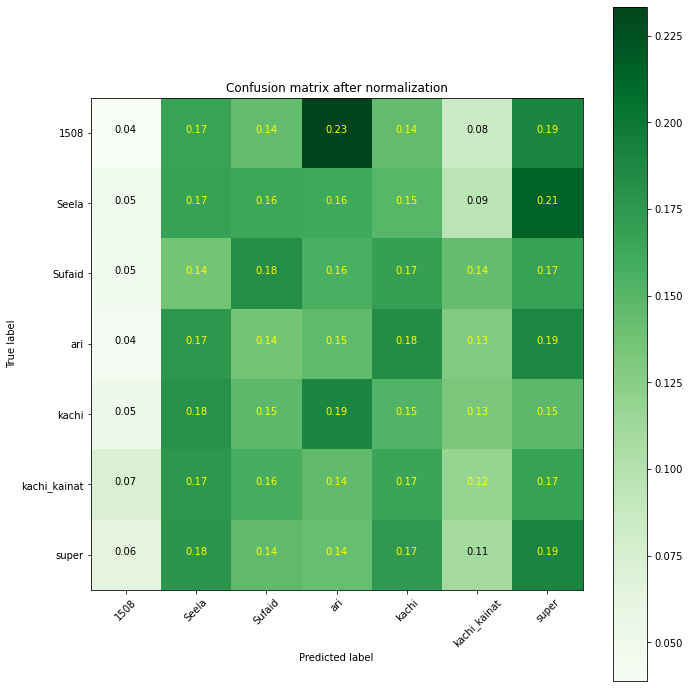

In [ ]:
# compute confusion matrix
cnf_matrix = confusion_matrix(y_test, y_pred)
np.set_printoptions(precision=4)

# plot normalized confusion matrix
plt.figure()
plot_confusion_matrix(cnf_matrix, classes=class_names, title='Confusion matrix after normalization')
plt.show()

In [ ]:
model.save("VGG16.h5")

In [ ]:
from keras.models import load_model
from PIL import Image, ImageOps
import numpy as np

In [ ]:
model = load_model('/content/vgg16.h5')

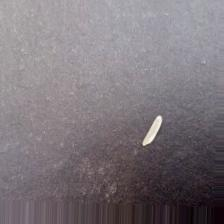

In [ ]:
from IPython.display import Image
Image('/content/drive/MyDrive/Dataset/Rice_Varieties/train_real/Seela/Seela_0_2991.jpeg', width=250, height=250)

In [ ]:
from PIL import Image

# open the image file
img = Image.open("/content/drive/MyDrive/Dataset/Rice_Varieties/train_real/Seela/Seela_0_2991.jpeg")

# set the desired size
new_size = (224, 224)

# resize the image
resized_img = img.resize(new_size)

# save the resized image
resized_img.save("/content/image.jpg")


In [ ]:
import cv2
import numpy as np

In [ ]:
import cv2

# load the image
img = cv2.imread("/content/image.jpg")
from google.colab.patches import cv2_imshow

In [ ]:
img = cv2.imread('/content/image.jpg', cv2.IMREAD_GRAYSCALE)

# Normalize pixel values to range of 0-1
img_norm = img.astype('float') / 255.0

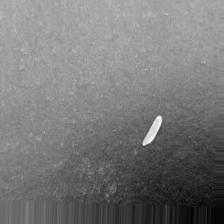

In [ ]:
from PIL import Image
import numpy as np

# Load image
img = Image.open('/content/1.jpg')
img_norm = np.array(img.convert('L'), dtype='float') / 255.0
normalized=Image.fromarray(np.uint8(img_norm * 255))
normalized.show()
normalized.save("normalized.jpg")

Texture features

In [ ]:
from skimage.feature import greycomatrix, greycoprops
from skimage.color import rgb2gray
import numpy as np
from skimage import io
from skimage import io, img_as_ubyte


# load the image and convert it to grayscale
img = rgb2gray(io.imread('/content/drive/MyDrive/Dataset/Rice_Varieties/train_real/Seela/Seela_0_2991.jpeg'))

In [ ]:
img_uint = img_as_ubyte(img)
# define the properties for the grey-level co-occurrence matrix (GLCM)
# define the properties for the grey-level co-occurrence matrix (GLCM)
d = 1
theta = [0, np.pi/4, np.pi/2, 3*np.pi/4]
levels = 256
symmetric = True
normed = True


In [ ]:
glcm = greycomatrix(img_uint, distances=[d], angles=theta, levels=levels, symmetric=symmetric, normed=normed)


/usr/local/lib/python3.9/dist-packages/skimage/feature/__init__.py:35: skimage_deprecation: Function ``greycomatrix`` is deprecated and will be removed in version 1.0. Use ``skimage.feature.graycomatrix`` instead.
  removed_version='1.0')


In [ ]:
# calculate the Haralick texture features from the GLCM
contrast = greycoprops(glcm, 'contrast')
dissimilarity = greycoprops(glcm, 'dissimilarity')
homogeneity = greycoprops(glcm, 'homogeneity')
energy = greycoprops(glcm, 'energy')
correlation = greycoprops(glcm, 'correlation')

/usr/local/lib/python3.9/dist-packages/skimage/feature/__init__.py:42: skimage_deprecation: Function ``greycoprops`` is deprecated and will be removed in version 1.0. Use ``skimage.feature.graycoprops`` instead.
  removed_version='1.0')
/usr/local/lib/python3.9/dist-packages/skimage/feature/__init__.py:42: skimage_deprecation: Function ``greycoprops`` is deprecated and will be removed in version 1.0. Use ``skimage.feature.graycoprops`` instead.
  removed_version='1.0')
/usr/local/lib/python3.9/dist-packages/skimage/feature/__init__.py:42: skimage_deprecation: Function ``greycoprops`` is deprecated and will be removed in version 1.0. Use ``skimage.feature.graycoprops`` instead.
  removed_version='1.0')
/usr/local/lib/python3.9/dist-packages/skimage/feature/__init__.py:42: skimage_deprecation: Function ``greycoprops`` is deprecated and will be removed in version 1.0. Use ``skimage.feature.graycoprops`` instead.
  removed_version='1.0')
/usr/local/lib/python3.9/dist-packages/skimage/featu

In [ ]:
# print the texture features
print(f"Contrast: {contrast}")
print(f"Dissimilarity: {dissimilarity}")
print(f"Homogeneity: {homogeneity}")
print(f"Energy: {energy}")
print(f"Correlation: {correlation}")

Contrast: [[32.23422486 57.86812524 25.30449231 39.72716121]]
Dissimilarity: [[3.51617553 4.70847996 3.27546445 4.50489654]]
Homogeneity: [[0.28724919 0.21442918 0.32090109 0.21561901]]
Energy: [[0.02762532 0.02413895 0.02845992 0.02399194]]
Correlation: [[0.99110988 0.9839757  0.99299874 0.98899836]]


Color

In [ ]:
from skimage import io, color
import numpy as np

In [ ]:
# load the image
img = io.imread('/content/drive/MyDrive/Dataset/Rice_Varieties/train_real/Seela/Seela_0_2991.jpeg')

In [ ]:
# convert the image to Lab color space
img_lab = color.rgb2lab(img)

# extract mean and standard deviation of the Lab color channels
mean_lab = np.mean(img_lab, axis=(0, 1))
std_lab = np.std(img_lab, axis=(0, 1))


In [ ]:
# convert the image to Lab color space
img_lab = color.rgb2lab(img)

In [ ]:
# extract mean and standard deviation of the Lab color channels
mean_lab = np.mean(img_lab, axis=(0, 1))
std_lab = np.std(img_lab, axis=(0, 1))

In [ ]:
# extract mean and standard deviation of the RGB color channels
mean_rgb = np.mean(img, axis=(0, 1))
std_rgb = np.std(img, axis=(0, 1))

In [ ]:
# print the color features
print(f"Lab mean: {mean_lab}")
print(f"Lab std: {std_lab}")
print(f"RGB mean: {mean_rgb}")
print(f"RGB std: {std_rgb}")

Lab mean: [49.45734833  3.93997787 -1.88165708]
Lab std: [17.5020891   1.83210161  1.84092157]
RGB mean: [124.31523039 117.0825295  122.39752073]
RGB std: [40.6807435  43.17385146 43.11981609]


In [ ]:
import cv2

# load the image
img = cv2.imread('/content/drive/MyDrive/Dataset/Rice_Varieties/train_real/Seela/Seela_0_2991.jpeg')

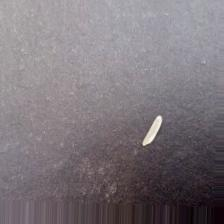

In [ ]:
# display the image
cv2_imshow(img)

In [ ]:
from tensorflow.keras.models import Model
import matplotlib.pyplot as plt
import tensorflow as tf

In [ ]:
model = tf.keras.applications.VGG16(weights='imagenet')

553467096/553467096 [==============================] - 7s 0us/step


In [ ]:
from PIL import Image
import numpy as np
from PIL import Image
import numpy as np
from tensorflow.keras.models import load_model

1/1 [==============================] - 0s 363ms/step


IndexError: ignored

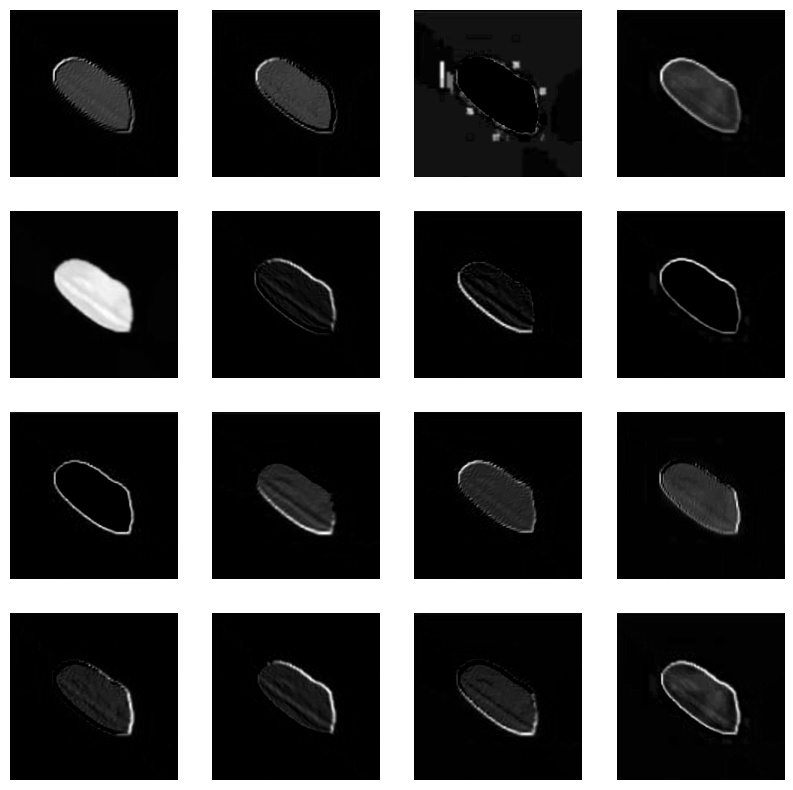

In [ ]:
layer_index = 2
layer = model.layers[layer_index]
feature_map_model = Model(inputs=model.inputs, outputs=layer.output)
img = Image.open("/content/rice.jpeg") # load your input image here
img = img.resize((224, 224))
img_array = np.array(img)
img_array = img_array.reshape((1,) + img_array.shape)
img = img_array
feature_maps = feature_map_model.predict(img)
fig, axs = plt.subplots(nrows=4, ncols=4, figsize=(10,10))
for i in range(feature_maps.shape[-1]):
    row = i // 4
    col = i % 4
    axs[row,col].imshow(feature_maps[0,:,:,i], cmap='gray')
    axs[row,col].axis('off')
plt.show()

1/1 [==============================] - 0s 399ms/step


IndexError: ignored

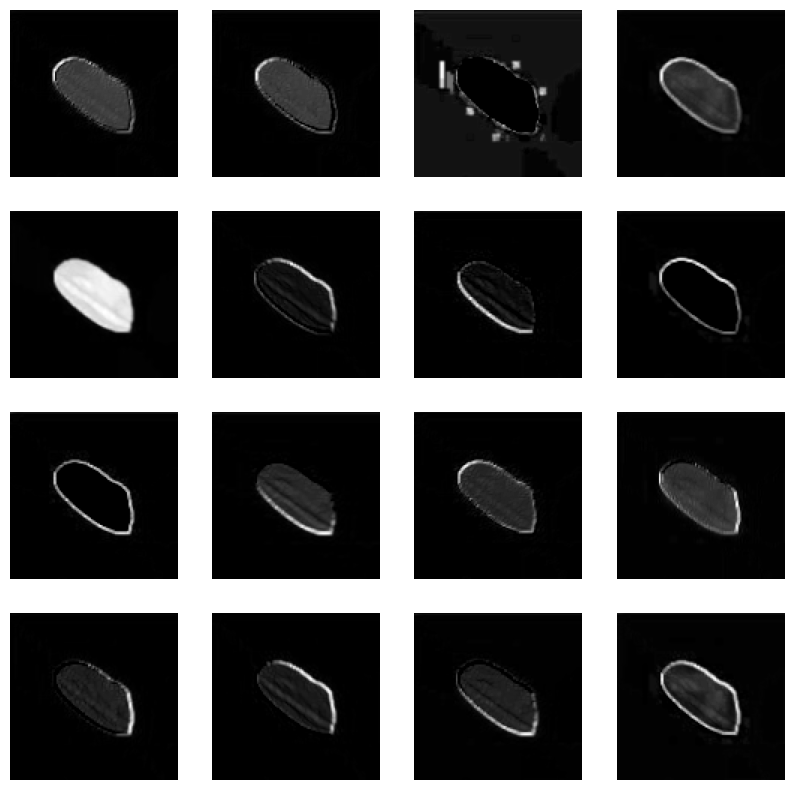

In [ ]:
layer_index = 3
layer = model.layers[layer_index]
feature_map_model = Model(inputs=model.inputs, outputs=layer.output)
img = Image.open("/content/rice.jpeg") # load your input image here
img = img.resize((224, 224))
img_array = np.array(img)
img_array = img_array.reshape((1,) + img_array.shape)
img = img_array
feature_maps = feature_map_model.predict(img)
fig, axs = plt.subplots(nrows=4, ncols=4, figsize=(10,10))
for i in range(feature_maps.shape[-1]):
    row = i // 4
    col = i % 4
    axs[row,col].imshow(feature_maps[0,:,:,i], cmap='gray')
    axs[row,col].axis('off')
plt.show()

1/1 [==============================] - 0s 265ms/step


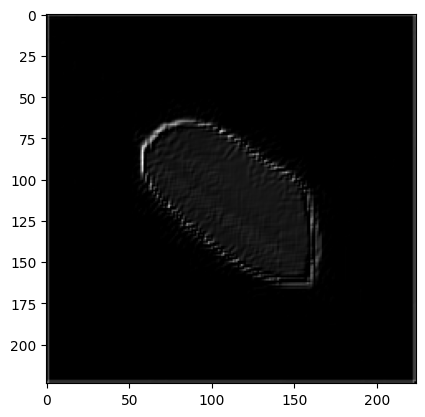

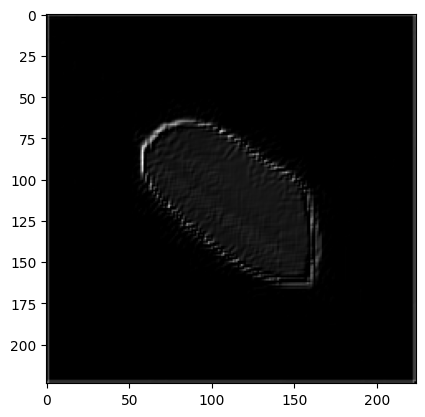

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications.vgg16 import VGG16
import matplotlib.pyplot as plt
model = VGG16(weights='imagenet', include_top=False)
# Load an example image
img_path = '/content/rice.jpeg'
img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
x = tf.keras.preprocessing.image.img_to_array(img)
x = tf.keras.applications.vgg16.preprocess_input(x)
x = tf.expand_dims(x, axis=0)
# Extract the output of the 5th convolutional layer
layer_name = 'block1_conv2'
layer_output = model.get_layer(layer_name).output
intermediate_model = tf.keras.models.Model(inputs=model.input, outputs=layer_output)
conv_output = intermediate_model.predict(x)
plt.imshow(conv_output[0, :, :, 0], cmap='gray')
plt.show()
# Plot the output
plt.imshow(conv_output[0, :, :, 0], cmap='gray')
plt.show()

1/1 [==============================] - 0s 152ms/step


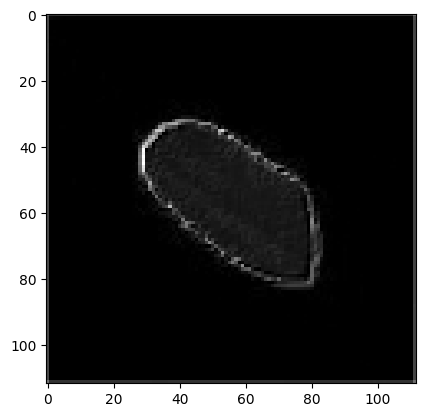

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications.vgg16 import VGG16
import matplotlib.pyplot as plt
model = VGG16(weights='imagenet', include_top=False)
# Load an example image
img_path = '/content/rice.jpeg'
img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
x = tf.keras.preprocessing.image.img_to_array(img)
x = tf.keras.applications.vgg16.preprocess_input(x)
x = tf.expand_dims(x, axis=0)
# Extract the output of the 5th convolutional layer
layer_name = 'block1_pool'
layer_output = model.get_layer(layer_name).output
intermediate_model = tf.keras.models.Model(inputs=model.input, outputs=layer_output)
conv_output = intermediate_model.predict(x)
plt.imshow(conv_output[0, :, :, 0], cmap='gray')
plt.show()


1/1 [==============================] - 1s 874ms/step


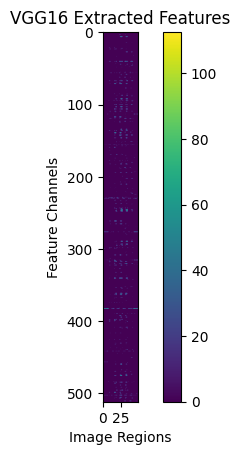

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.preprocessing import image

# Load pre-trained VGG16 model without top classification layers
base_model = VGG16(weights='imagenet', include_top=False)

# Load and preprocess an example image
image_path = '/content/super.jpeg'
img = image.load_img(image_path, target_size=(224, 224))
img_array = image.img_to_array(img)
expanded_img_array = np.expand_dims(img_array, axis=0)
preprocessed_img = preprocess_input(expanded_img_array)

# Extract features from the image using VGG16
features = base_model.predict(preprocessed_img)

# Reshape features for visualization
features_reshaped = features.reshape((-1, features.shape[-1]))

# Visualize the extracted features using a heatmap
plt.imshow(features_reshaped.T, cmap='viridis')
plt.title('VGG16 Extracted Features')
plt.xlabel('Image Regions')
plt.ylabel('Feature Channels')
plt.colorbar()
plt.show()


1/1 [==============================] - 1s 1s/step


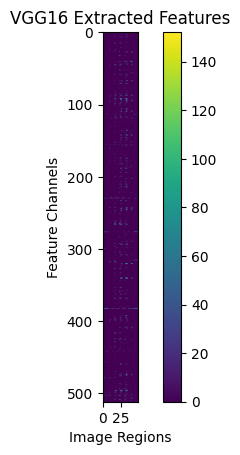

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.preprocessing import image

# Load pre-trained VGG16 model without top classification layers
base_model = VGG16(weights='imagenet', include_top=False)

# Load and preprocess an example image
image_path = '/content/sufaid.jpeg'
img = image.load_img(image_path, target_size=(224, 224))
img_array = image.img_to_array(img)
expanded_img_array = np.expand_dims(img_array, axis=0)
preprocessed_img = preprocess_input(expanded_img_array)

# Extract features from the image using VGG16
features = base_model.predict(preprocessed_img)

# Reshape features for visualization
features_reshaped = features.reshape((-1, features.shape[-1]))

# Visualize the extracted features using a heatmap
plt.imshow(features_reshaped.T, cmap='viridis')
plt.title('VGG16 Extracted Features')
plt.xlabel('Image Regions')
plt.ylabel('Feature Channels')
plt.colorbar()
plt.show()


1/1 [==============================] - 1s 843ms/step


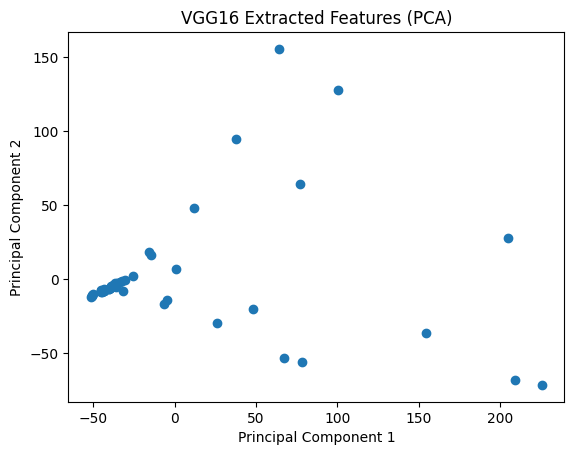

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.preprocessing import image
from sklearn.decomposition import PCA

# Load pre-trained VGG16 model without top classification layers
base_model = VGG16(weights='imagenet', include_top=False)

# Load and preprocess an example image
image_path = '/content/super.jpeg'
img = image.load_img(image_path, target_size=(224, 224))
img_array = image.img_to_array(img)
expanded_img_array = np.expand_dims(img_array, axis=0)
preprocessed_img = preprocess_input(expanded_img_array)

# Extract features from the image using VGG16
features = base_model.predict(preprocessed_img)

# Reshape features for PCA
features_reshaped = features.reshape((-1, features.shape[-1]))

# Perform PCA to reduce dimensions to 2 for visualization
pca = PCA(n_components=2)
features_pca = pca.fit_transform(features_reshaped)

# Visualize the extracted features using a scatter plot
plt.scatter(features_pca[:, 0], features_pca[:, 1])
plt.title('VGG16 Extracted Features (PCA)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()


1/1 [==============================] - 1s 1s/step


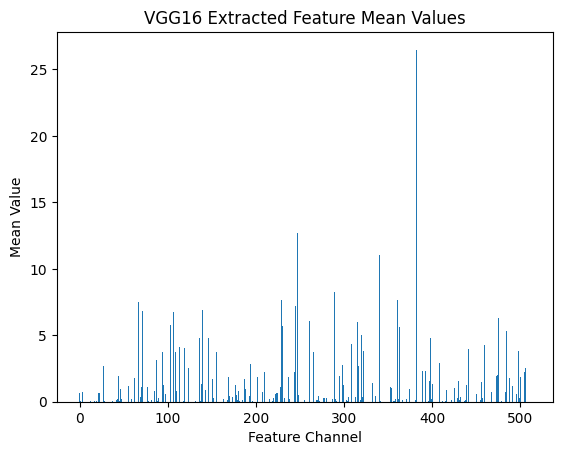

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.preprocessing import image

# Load pre-trained VGG16 model without top classification layers
base_model = VGG16(weights='imagenet', include_top=False)

# Load and preprocess an example image
image_path = '/content/super.jpeg'
img = image.load_img(image_path, target_size=(224, 224))
img_array = image.img_to_array(img)
expanded_img_array = np.expand_dims(img_array, axis=0)
preprocessed_img = preprocess_input(expanded_img_array)

# Extract features from the image using VGG16
features = base_model.predict(preprocessed_img)

# Calculate the mean values of the extracted features
features_mean = np.mean(features, axis=(0, 1, 2))

# Create a bar graph to represent the mean feature values
plt.bar(range(len(features_mean)), features_mean)
plt.title('VGG16 Extracted Feature Mean Values')
plt.xlabel('Feature Channel')
plt.ylabel('Mean Value')
plt.show()


1/1 [==============================] - 1s 1s/step


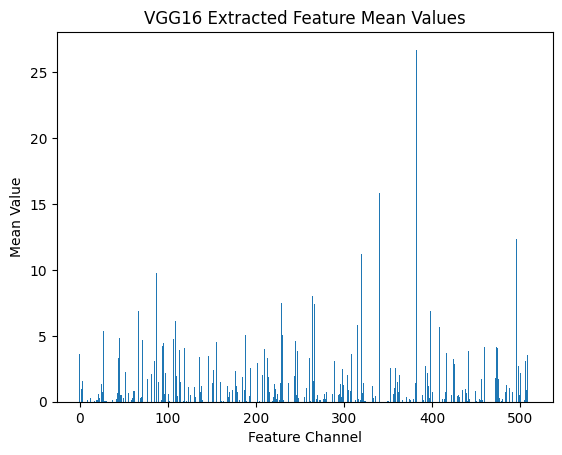

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.preprocessing import image

# Load pre-trained VGG16 model without top classification layers
base_model = VGG16(weights='imagenet', include_top=False)

# Load and preprocess an example image
image_path = '/content/sufaid.jpeg'
img = image.load_img(image_path, target_size=(224, 224))
img_array = image.img_to_array(img)
expanded_img_array = np.expand_dims(img_array, axis=0)
preprocessed_img = preprocess_input(expanded_img_array)

# Extract features from the image using VGG16
features = base_model.predict(preprocessed_img)

# Calculate the mean values of the extracted features
features_mean = np.mean(features, axis=(0, 1, 2))

# Create a bar graph to represent the mean feature values
plt.bar(range(len(features_mean)), features_mean)
plt.title('VGG16 Extracted Feature Mean Values')
plt.xlabel('Feature Channel')
plt.ylabel('Mean Value')
plt.show()


1/1 [==============================] - 0s 452ms/step


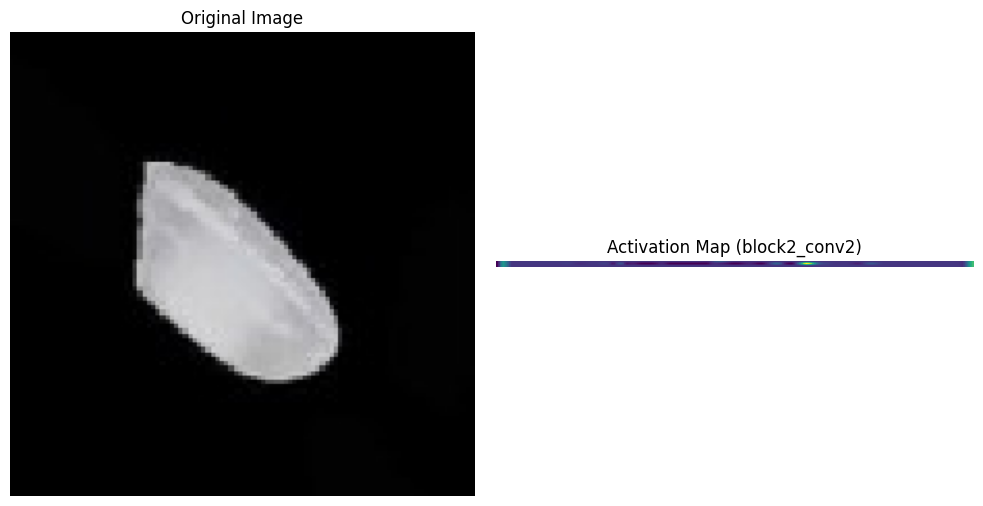

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import Model
import cv2

# Load pre-trained VGG16 model without top classification layers
base_model = VGG16(weights='imagenet', include_top=False)

# Load and preprocess an example image
image_path = '/content/sufaid.jpeg'
img = image.load_img(image_path, target_size=(224, 224))
img_array = image.img_to_array(img)
expanded_img_array = np.expand_dims(img_array, axis=0)
preprocessed_img = preprocess_input(expanded_img_array)

# Choose a layer for visualization (e.g., block1_conv1)
layer_name = 'block2_conv2'
model = Model(inputs=base_model.input, outputs=base_model.get_layer(layer_name).output)
activations = model.predict(preprocessed_img)

# Visualize activations of a specific filter
filter_index = 0
activation_map = activations[0, :, :, filter_index]

# Upsample the activation map to match the original image size
activation_map = cv2.resize(activation_map, img_array.shape[1:3])

# Normalize the activation map for visualization
activation_map -= activation_map.min()
activation_map /= activation_map.max()

# Plot the original image and the activation map
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(activation_map, cmap='viridis')
plt.title(f'Activation Map ({layer_name})')
plt.axis('off')

plt.tight_layout()
plt.show()


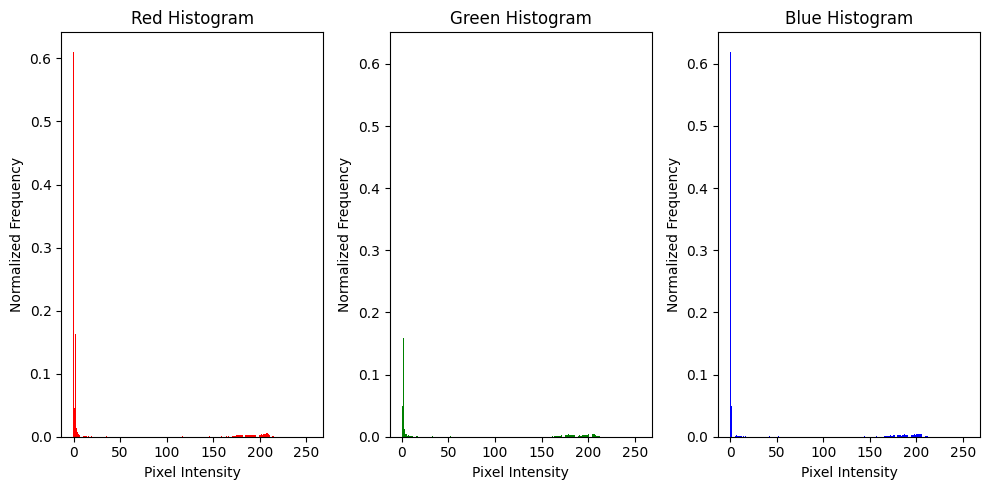

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load an example image
image_path = '/content/sufaid.jpeg'
image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Calculate color histograms
hist_r = cv2.calcHist([image], [0], None, [256], [0, 256])
hist_g = cv2.calcHist([image], [1], None, [256], [0, 256])
hist_b = cv2.calcHist([image], [2], None, [256], [0, 256])

# Normalize histograms
hist_r /= hist_r.sum()
hist_g /= hist_g.sum()
hist_b /= hist_b.sum()

# Create a bar graph to represent the color histograms
plt.figure(figsize=(10, 5))

plt.subplot(1, 3, 1)
plt.bar(range(256), hist_r.ravel(), color='red')
plt.title('Red Histogram')
plt.xlabel('Pixel Intensity')
plt.ylabel('Normalized Frequency')

plt.subplot(1, 3, 2)
plt.bar(range(256), hist_g.ravel(), color='green')
plt.title('Green Histogram')
plt.xlabel('Pixel Intensity')
plt.ylabel('Normalized Frequency')

plt.subplot(1, 3, 3)
plt.bar(range(256), hist_b.ravel(), color='blue')
plt.title('Blue Histogram')
plt.xlabel('Pixel Intensity')
plt.ylabel('Normalized Frequency')

plt.tight_layout()
plt.show()


1/1 [==============================] - 1s 524ms/step


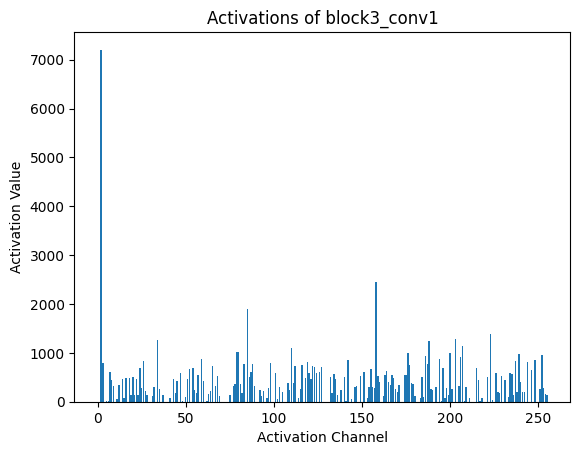

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import Model

# Load pre-trained VGG16 model without top classification layers
base_model = VGG16(weights='imagenet', include_top=False)

# Load and preprocess an example image
image_path = '/content/sufaid.jpeg'
img = image.load_img(image_path, target_size=(224, 224))
img_array = image.img_to_array(img)
expanded_img_array = np.expand_dims(img_array, axis=0)
preprocessed_img = preprocess_input(expanded_img_array)

# Choose a layer for visualization (e.g., block3_conv1)
layer_name = 'block3_conv1'
model = Model(inputs=base_model.input, outputs=base_model.get_layer(layer_name).output)
activations = model.predict(preprocessed_img)

# Reshape activations for visualization
activations_reshaped = activations.reshape((-1, activations.shape[3]))

# Create a bar graph to represent the activations
plt.bar(range(len(activations_reshaped[0])), activations_reshaped[0])
plt.title(f'Activations of {layer_name}')
plt.xlabel('Activation Channel')
plt.ylabel('Activation Value')
plt.show()


1/1 [==============================] - 0s 429ms/step


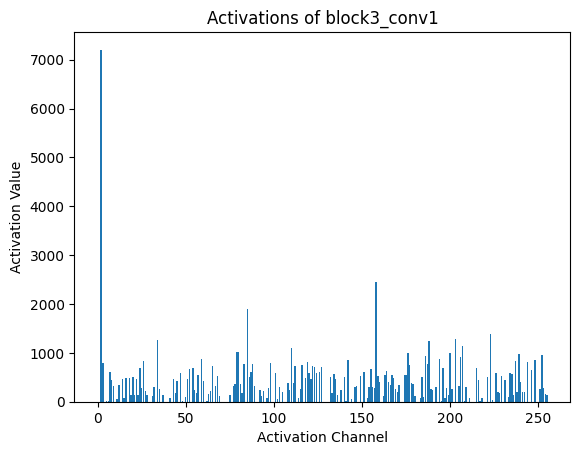

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import Model

# Load pre-trained VGG16 model without top classification layers
base_model = VGG16(weights='imagenet', include_top=False)

# Load and preprocess an example image
image_path = '/content/kachi_kainat.jpeg'
img = image.load_img(image_path, target_size=(224, 224))
img_array = image.img_to_array(img)
expanded_img_array = np.expand_dims(img_array, axis=0)
preprocessed_img = preprocess_input(expanded_img_array)

# Choose a layer for visualization (e.g., block3_conv1)
layer_name = 'block3_conv1'
model = Model(inputs=base_model.input, outputs=base_model.get_layer(layer_name).output)
activations = model.predict(preprocessed_img)

# Reshape activations for visualization
activations_reshaped = activations.reshape((-1, activations.shape[3]))

# Create a bar graph to represent the activations
plt.bar(range(len(activations_reshaped[0])), activations_reshaped[0])
plt.title(f'Activations of {layer_name}')
plt.xlabel('Activation Channel')
plt.ylabel('Activation Value')
plt.show()


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import Model
from sklearn.metrics.pairwise import euclidean_distances

# Load pre-trained VGG16 model without top classification layers
base_model = VGG16(weights='imagenet', include_top=False)

# Load and preprocess two example images
image_path_1 = '/content/kachi_kainat.jpeg'
image_path_2 = '/content/sufaid.jpeg'

img_1 = image.load_img(image_path_1, target_size=(224, 224))
img_array_1 = image.img_to_array(img_1)
expanded_img_array_1 = np.expand_dims(img_array_1, axis=0)
preprocessed_img_1 = preprocess_input(expanded_img_array_1)

img_2 = image.load_img(image_path_2, target_size=(224, 224))
img_array_2 = image.img_to_array(img_2)
expanded_img_array_2 = np.expand_dims(img_array_2, axis=0)
preprocessed_img_2 = preprocess_input(expanded_img_array_2)

# Extract features from a layer (e.g., block5_conv3)
layer_name = 'block5_conv3'
model = Model(inputs=base_model.input, outputs=base_model.get_layer(layer_name).output)

features_1 = model.predict(preprocessed_img_1)
features_2 = model.predict(preprocessed_img_2)

# Flatten the features for Euclidean distance calculation
features_1_flat = features_1.reshape(-1)
features_2_flat = features_2.reshape(-1)

# Calculate Euclidean distances between features
distance = np.linalg.norm(features_1_flat - features_2_flat)

print(f'Euclidean Distance: {distance}')


1/1 [==============================] - 1s 769ms/step
Euclidean Distance: 1750.5916748046875


In [ ]:


# Load and preprocess two example images
image_path_1 = '/content/kachi_kainat.jpeg'
image_path_2 = '/content/sufaid.jpeg'



import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import Model

# Load pre-trained VGG16 model without top classification layers
base_model = VGG16(weights='imagenet', include_top=False)



img_1 = image.load_img(image_path_1, target_size=(224, 224))
img_array_1 = image.img_to_array(img_1)
expanded_img_array_1 = np.expand_dims(img_array_1, axis=0)
preprocessed_img_1 = preprocess_input(expanded_img_array_1)

img_2 = image.load_img(image_path_2, target_size=(224, 224))
img_array_2 = image.img_to_array(img_2)
expanded_img_array_2 = np.expand_dims(img_array_2, axis=0)
preprocessed_img_2 = preprocess_input(expanded_img_array_2)

# Extract features from a layer (e.g., block5_conv3)
layer_name = 'block5_conv3'
model = Model(inputs=base_model.input, outputs=base_model.get_layer(layer_name).output)

features_1 = model.predict(preprocessed_img_1)
features_2 = model.predict(preprocessed_img_2)

# Calculate the absolute differences between the features
feature_diff = np.abs(features_1 - features_2)

# Visualize the differences using a heatmap
plt.figure(figsize=(10, 5))
sns.heatmap(feature_diff[0], cmap='coolwarm', annot=True, fmt=".2f")
plt.title(f'Absolute Feature Differences Heatmap ({layer_name})')
plt.xlabel('Feature Map Channel')
plt.ylabel('Feature Map Channel')
plt.show()

